 Step 1: Dataset collection and understanding

In [2]:
import pandas as pd

# Show all columns when printing (pandas hides middle columns by default)
pd.set_option("display.max_columns", None)

# 1. Load the file
df = pd.read_csv("Health Insurance Fraud Claims.csv")

In [3]:
# Show all columns when printing (pandas hides middle columns by default)
pd.set_option("display.max_columns", None)

In [4]:
# 2. Shape: (rows, columns)
print(df.shape)

(4500, 19)


In [6]:
# 3. First 5 rows
df.head()

,ClaimID,PatientID,ProviderID,ClaimAmount,ClaimDate,DiagnosisCode,ProcedureCode,PatientAge,PatientGender,ProviderSpecialty,ClaimStatus,PatientIncome,PatientMaritalStatus,PatientEmploymentStatus,ProviderLocation,ClaimType,ClaimSubmissionMethod,Cluster,ClaimLegitimacy
0,4d76c7f7-d36a-4139-b451-a9a4ad10d7d5,19cf2638-3ec0-4ed9-9995-d9ba4553813a,a3d0cc80-dffe-40ff-a302-23c8ffeedb36,7820.52,2024-07-08 00:00:00,Ta150,iO013,96,F,Orthopedics,Pending,57595.11,Single,Employed,New Alishaview,Inpatient,Paper,3,Legitimate
1,e35193b4-3609-492b-866a-98de19317e9c,5c4bb6c5-4dd3-4a86-85fa-f36c0d8debff,a9f25acf-92b8-45e2-9cef-87bd07d0a591,5453.86,2024-07-08 00:00:00,Fo766,jR349,95,M,Cardiology,Denied,140772.72,Widowed,Employed,East Curtis,Inpatient,Online,2,Legitimate
2,1f3fa373-25ed-4ff4-b6c7-38dcb2fb297f,777866e0-4d10-45a8-a7b4-dbdaa26d5a81,951b1e08-9948-4956-80e5-9277f16bd290,8229.86,2024-07-08 00:00:00,AX876,uU479,10,M,Cardiology,Pending,69803.19,Married,Student,Lake Jennifer,Emergency,Online,3,Legitimate
3,af6a68f4-8319-47b1-a28b-77de01572851,9d7c53ee-eb1a-4f07-9e3a-e86cf82e9f0f,de9e193a-f9a1-4d63-9345-aefe75694628,9519.16,2024-07-08 00:00:00,SQ441,Xs264,59,F,Cardiology,Pending,135530.12,Married,Employed,Martinstad,Routine,Phone,2,Legitimate
4,417fe944-79d2-4610-81c4-a2d496f29ee4,db14b0ca-ac2a-4e83-b085-947ea32e7587,5c7d7045-71b6-4c15-937c-43e4cfe65bf4,3226.15,2024-07-08 00:00:00,FK970,PV476,36,F,Neurology,Approved,36995.52,Divorced,Unemployed,Thomasfurt,Inpatient,Phone,1,Legitimate


In [7]:
# 4. Column names, data types, non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ClaimID                  4500 non-null   object 
 1   PatientID                4500 non-null   object 
 2   ProviderID               4500 non-null   object 
 3   ClaimAmount              4500 non-null   float64
 4   ClaimDate                4500 non-null   object 
 5   DiagnosisCode            4500 non-null   object 
 6   ProcedureCode            4500 non-null   object 
 7   PatientAge               4500 non-null   int64  
 8   PatientGender            4500 non-null   object 
 9   ProviderSpecialty        4500 non-null   object 
 10  ClaimStatus              4500 non-null   object 
 11  PatientIncome            4500 non-null   float64
 12  PatientMaritalStatus     4500 non-null   object 
 13  PatientEmploymentStatus  4500 non-null   object 
 14  ProviderLocation        

In [8]:
# 5. Missing values per column
print(df.isnull().sum())

ClaimID                    0
PatientID                  0
ProviderID                 0
ClaimAmount                0
ClaimDate                  0
DiagnosisCode              0
ProcedureCode              0
PatientAge                 0
PatientGender              0
ProviderSpecialty          0
ClaimStatus                0
PatientIncome              0
PatientMaritalStatus       0
PatientEmploymentStatus    0
ProviderLocation           0
ClaimType                  0
ClaimSubmissionMethod      0
Cluster                    0
ClaimLegitimacy            0
dtype: int64


In [9]:
# 6. Count of fully duplicated rows
print(df.duplicated().sum())

0


In [10]:
# 7. Number of unique values per column
print(df.nunique())

ClaimID                    4500
PatientID                  4500
ProviderID                 4500
ClaimAmount                4490
ClaimDate                   731
DiagnosisCode              4495
ProcedureCode              4495
PatientAge                  100
PatientGender                 2
ProviderSpecialty             5
ClaimStatus                   3
PatientIncome              4500
PatientMaritalStatus          4
PatientEmploymentStatus       4
ProviderLocation           3876
ClaimType                     4
ClaimSubmissionMethod         3
Cluster                       4
ClaimLegitimacy               2
dtype: int64


In [11]:
# 8. Statistics for numeric columns
print(df.describe())

       ClaimAmount   PatientAge  PatientIncome      Cluster
count  4500.000000  4500.000000    4500.000000  4500.000000
mean   5014.203867    49.838444   84384.284084     1.503111
std    2866.291066    28.790471   37085.908878     1.127261
min     100.120000     0.000000   20006.870000     0.000000
25%    2509.072500    25.000000   52791.905000     0.000000
50%    5053.765000    50.500000   84061.205000     2.000000
75%    7462.452500    75.000000  115768.417500     3.000000
max    9997.200000    99.000000  149957.520000     3.000000


In [13]:
# 9. Statistics for text columns
df.describe(include="object")

,ClaimID,PatientID,ProviderID,ClaimDate,DiagnosisCode,ProcedureCode,PatientGender,ProviderSpecialty,ClaimStatus,PatientMaritalStatus,PatientEmploymentStatus,ProviderLocation,ClaimType,ClaimSubmissionMethod,ClaimLegitimacy
count,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500
unique,4500,4500,4500,731,4495,4495,2,5,3,4,4,3876,4,3,2
top,4d76c7f7-d36a-4139-b451-a9a4ad10d7d5,19cf2638-3ec0-4ed9-9995-d9ba4553813a,a3d0cc80-dffe-40ff-a302-23c8ffeedb36,2023-06-20 00:00:00,iR323,zW098,F,Pediatrics,Approved,Married,Employed,North Michael,Outpatient,Paper,Legitimate
freq,1,1,1,15,2,3,2282,955,1522,1181,1188,8,1152,1544,4230


In [14]:
# 10. Target variable distribution (counts, then proportions)
print(df["ClaimLegitimacy"].value_counts())
print(df["ClaimLegitimacy"].value_counts(normalize=True))

ClaimLegitimacy
Legitimate    4230
Fraud          270
Name: count, dtype: int64
ClaimLegitimacy
Legitimate    0.94
Fraud         0.06
Name: proportion, dtype: float64


Step 2: Data Cleaning

In [15]:
# 1. Work on a copy so the original stays untouched
df_clean = df.copy()

In [16]:
# 2. Convert ClaimDate from text to a real datetime type
df_clean["ClaimDate"] = pd.to_datetime(df_clean["ClaimDate"])
print(df_clean["ClaimDate"].dtype)
print(df_clean["ClaimDate"].min(), df_clean["ClaimDate"].max())

datetime64[ns]
2022-07-09 00:00:00 2024-07-08 00:00:00


In [17]:
# 3. Duplicate check: whole rows, then ignoring the ID column
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicates ignoring ClaimID:", df_clean.drop(columns="ClaimID").duplicated().sum())

Duplicate rows: 0
Duplicates ignoring ClaimID: 0


In [18]:
# 4. Missing values (re-check; should match Step 1)
print(df_clean.isnull().sum().sum())

0


In [19]:
# 5. Text consistency: stray spaces and unexpected category labels
cat_cols = ["PatientGender", "ClaimStatus", "ClaimType", "ClaimSubmissionMethod",
            "ProviderSpecialty", "PatientMaritalStatus", "PatientEmploymentStatus"]
for col in cat_cols:
    print(col, sorted(df_clean[col].unique()))
    print("  rows with extra spaces:", (df_clean[col] != df_clean[col].str.strip()).sum())


PatientGender ['F', 'M']
  rows with extra spaces: 0
ClaimStatus ['Approved', 'Denied', 'Pending']
  rows with extra spaces: 0
ClaimType ['Emergency', 'Inpatient', 'Outpatient', 'Routine']
  rows with extra spaces: 0
ClaimSubmissionMethod ['Online', 'Paper', 'Phone']
  rows with extra spaces: 0
ProviderSpecialty ['Cardiology', 'General Practice', 'Neurology', 'Orthopedics', 'Pediatrics']
  rows with extra spaces: 0
PatientMaritalStatus ['Divorced', 'Married', 'Single', 'Widowed']
  rows with extra spaces: 0
PatientEmploymentStatus ['Employed', 'Retired', 'Student', 'Unemployed']
  rows with extra spaces: 0


In [20]:
# 6. Impossible or suspicious numeric values
print(df_clean[["ClaimAmount", "PatientAge", "PatientIncome"]].agg(["min", "max"]))
print("Amount <= 0:", (df_clean["ClaimAmount"] <= 0).sum())


     ClaimAmount  PatientAge  PatientIncome
min       100.12           0       20006.87
max      9997.20          99      149957.52
Amount <= 0: 0


In [21]:
# 7. Outlier check with the IQR rule
for col in ["ClaimAmount", "PatientIncome"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    print(col, "outliers:", n_out)

ClaimAmount outliers: 0
PatientIncome outliers: 0


In [23]:
 #8. Drop columns that can't help a model
df_clean = df_clean.drop(columns=["ClaimID", "PatientID", "ProviderID"])

In [24]:
# 9. Encode the target as numbers: Fraud = 1, Legitimate = 0
df_clean["Fraud"] = (df_clean["ClaimLegitimacy"] == "Fraud").astype(int)
print(df_clean["Fraud"].value_counts())

print(df_clean.shape)

Fraud
0    4230
1     270
Name: count, dtype: int64
(4500, 17)


Step 3: Exploratory data analysis (EDA)

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
sns.set_theme(style="whitegrid")


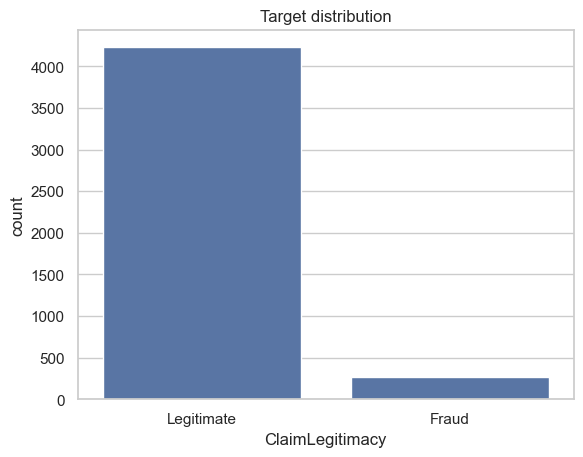

In [29]:
# 1. Target distribution
sns.countplot(data=df_clean, x="ClaimLegitimacy")
plt.title("Target distribution")
plt.show()

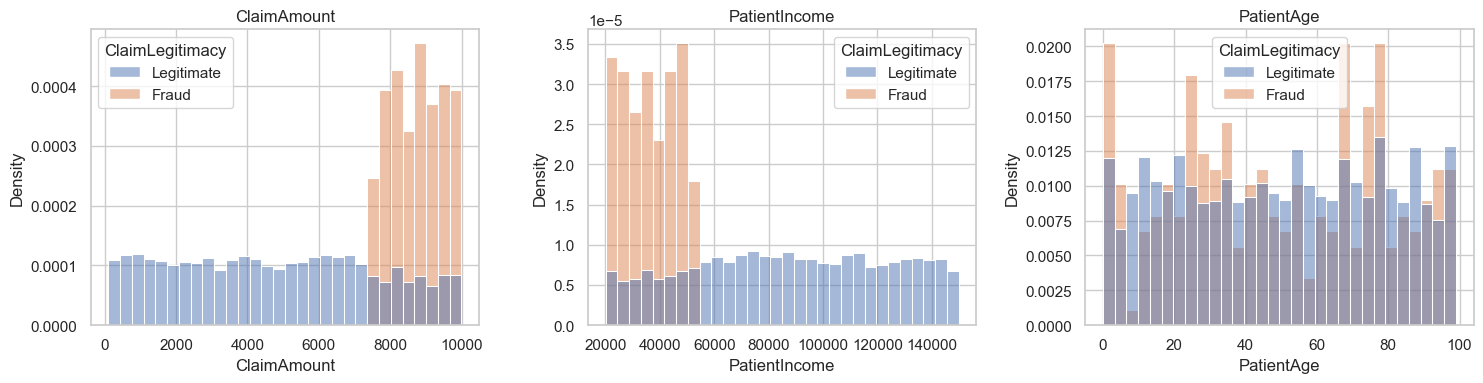

In [30]:
# 2. Numeric features: histogram split by class
num_cols = ["ClaimAmount", "PatientIncome", "PatientAge"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df_clean, x=col, hue="ClaimLegitimacy",
                 stat="density", common_norm=False, bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

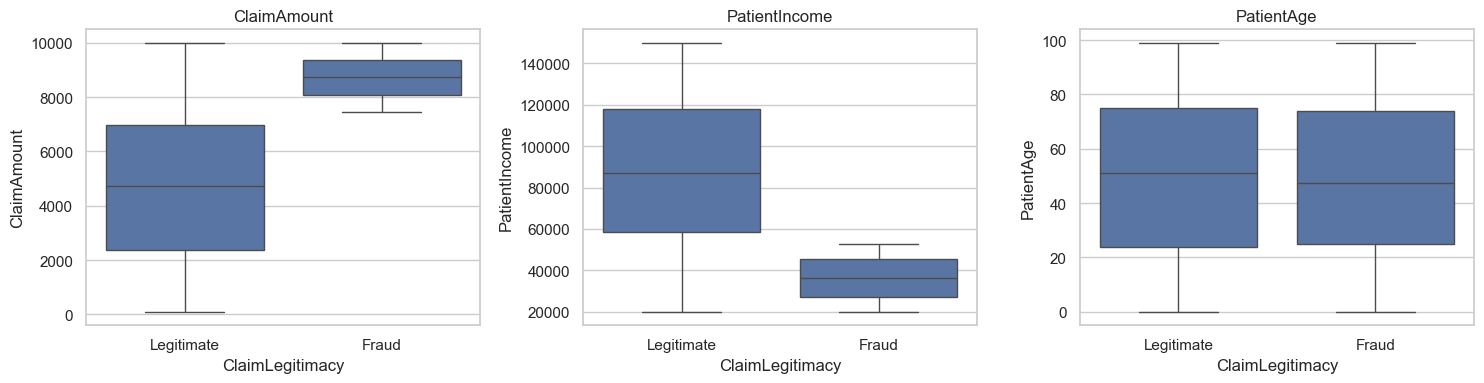

In [31]:
# 3. Boxplots: numeric feature vs target
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df_clean, x="ClaimLegitimacy", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

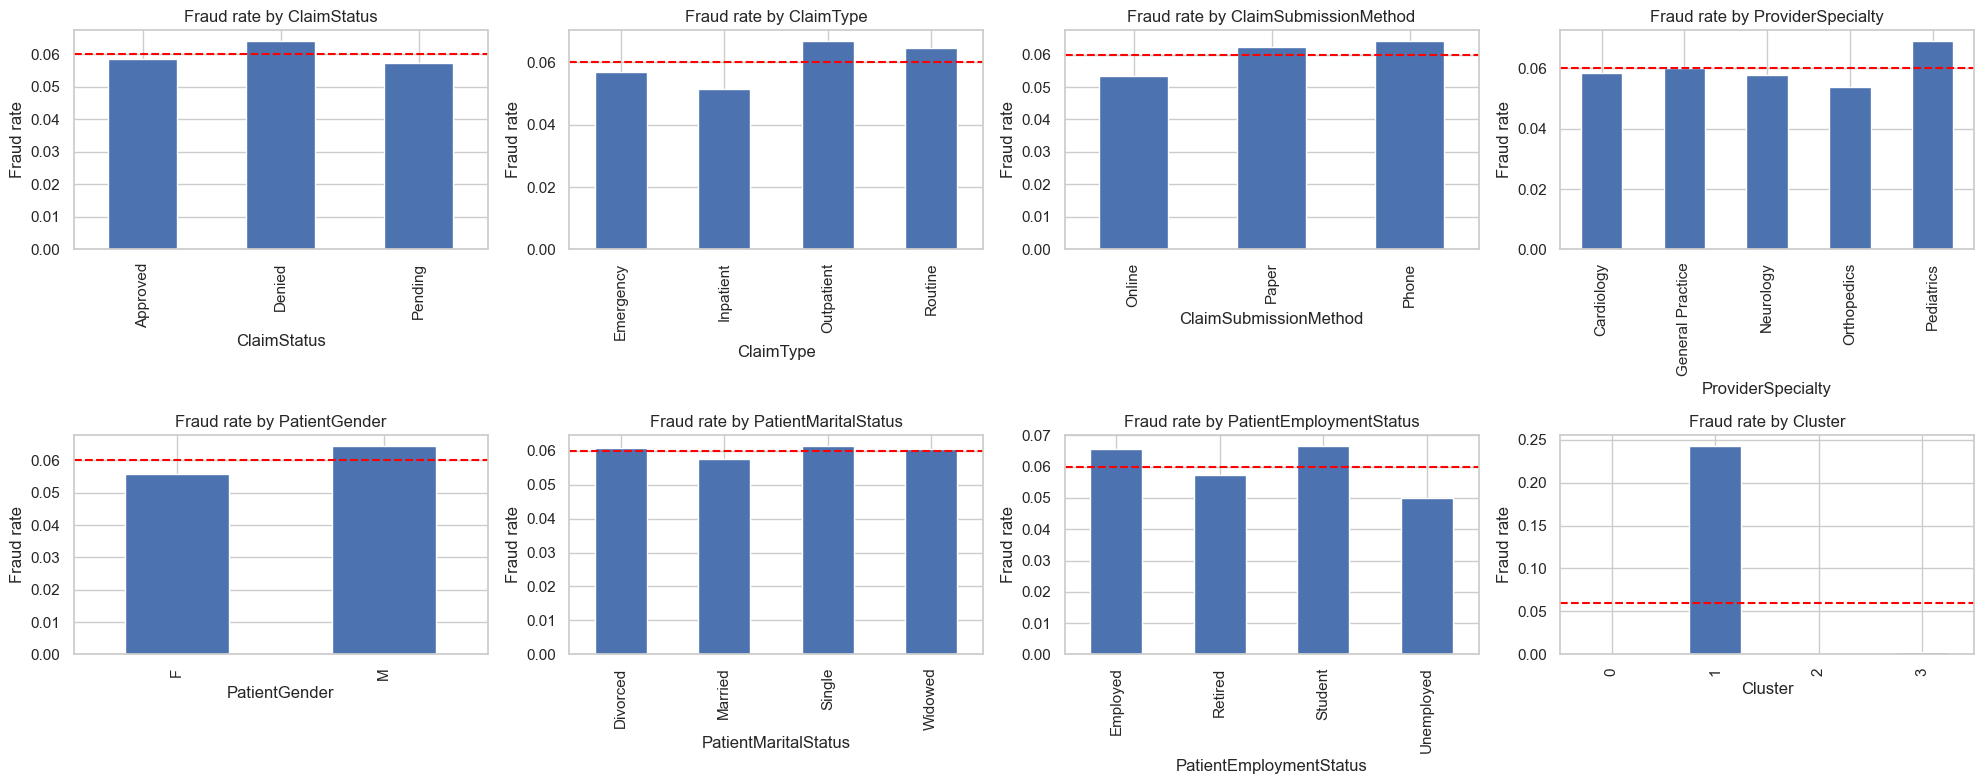

In [32]:
# 4. Categorical features: fraud RATE per category
cat_cols = ["ClaimStatus", "ClaimType", "ClaimSubmissionMethod", "ProviderSpecialty",
            "PatientGender", "PatientMaritalStatus", "PatientEmploymentStatus", "Cluster"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df_clean.groupby(col)["Fraud"].mean()
    rate.plot(kind="bar", ax=ax)
    ax.axhline(df_clean["Fraud"].mean(), color="red", linestyle="--")
    ax.set_title(f"Fraud rate by {col}")
    ax.set_ylabel("Fraud rate")
plt.tight_layout()
plt.show()

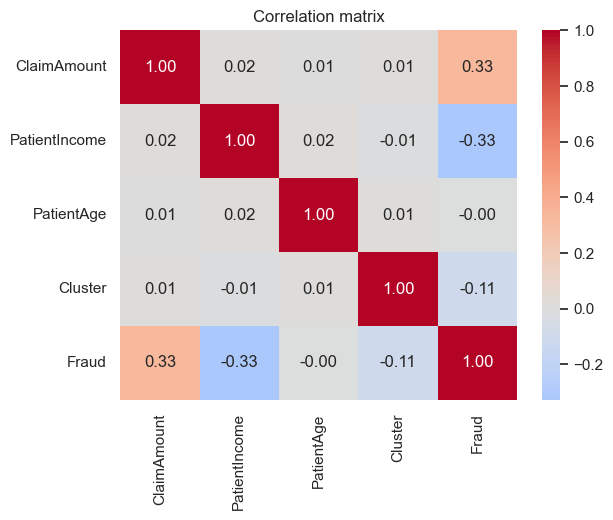

In [33]:
# 5. Correlation heatmap (numeric columns only)
corr = df_clean[["ClaimAmount", "PatientIncome", "PatientAge", "Cluster", "Fraud"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

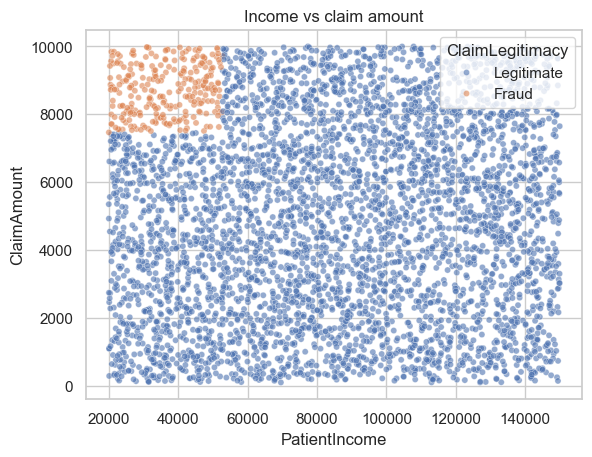

In [34]:
# 6. Two-feature scatter plot, coloured by class
sns.scatterplot(data=df_clean, x="PatientIncome", y="ClaimAmount",
                hue="ClaimLegitimacy", alpha=0.6, s=20)
plt.title("Income vs claim amount")
plt.show()

In [35]:
# 7. Fraud rate over time (by quarter)
quarterly = df_clean.groupby(df_clean["ClaimDate"].dt.to_period("Q"))["Fraud"].agg(["mean", "size"])
print(quarterly)

               mean  size
ClaimDate                
2022Q3     0.063618   503
2022Q4     0.065858   577
2023Q1     0.054867   565
2023Q2     0.060606   594
2023Q3     0.072790   577
2023Q4     0.062827   573
2024Q1     0.048649   555
2024Q2     0.050584   514
2024Q3     0.047619    42


Step 4: Feature engineering, selection and preprocessing

In [37]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


In [38]:
df_fe = df_clean.copy()   # df_clean comes from Step 2


In [39]:
# 1. Feature engineering
df_fe["ClaimMonth"] = df_fe["ClaimDate"].dt.month
df_fe["AmountToIncome"] = df_fe["ClaimAmount"] / df_fe["PatientIncome"]
df_fe["AgeGroup"] = pd.cut(df_fe["PatientAge"],
                           bins=[-1, 17, 39, 64, 120],
                           labels=["Child", "YoungAdult", "Adult", "Senior"])

In [40]:
# 2. Drop columns we decided not to use
drop_cols = ["ClaimLegitimacy", "ClaimDate", "DiagnosisCode",
             "ProcedureCode", "ProviderLocation", "Cluster"]
df_fe = df_fe.drop(columns=drop_cols)

In [41]:
# 3. Separate target (y) from features (X)
y = df_fe.pop("Fraud")
X = df_fe
print(X.shape, X.columns.tolist())

(4500, 13) ['ClaimAmount', 'PatientAge', 'PatientGender', 'ProviderSpecialty', 'ClaimStatus', 'PatientIncome', 'PatientMaritalStatus', 'PatientEmploymentStatus', 'ClaimType', 'ClaimSubmissionMethod', 'ClaimMonth', 'AmountToIncome', 'AgeGroup']


In [42]:
# 4. Train/test split BEFORE any fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape, y_train.mean(), y_test.mean())

(3600, 13) (900, 13) 0.06 0.06


In [43]:
# 5. Feature selection with mutual information (training data only)
X_enc = pd.get_dummies(X_train, drop_first=True).astype(float)
mi = pd.Series(mutual_info_classif(X_enc, y_train, random_state=42),
               index=X_enc.columns).sort_values(ascending=False)
print(mi.round(4))

AmountToIncome                        0.1528
ClaimAmount                           0.0863
PatientIncome                         0.0862
ClaimStatus_Denied                    0.0070
PatientMaritalStatus_Married          0.0062
ClaimType_Inpatient                   0.0056
PatientGender_M                       0.0052
AgeGroup_Senior                       0.0050
ProviderSpecialty_Pediatrics          0.0049
ClaimMonth                            0.0040
PatientEmploymentStatus_Unemployed    0.0038
AgeGroup_Adult                        0.0035
PatientMaritalStatus_Widowed          0.0032
ProviderSpecialty_General Practice    0.0026
PatientEmploymentStatus_Retired       0.0020
ClaimSubmissionMethod_Paper           0.0008
PatientEmploymentStatus_Student       0.0004
PatientAge                            0.0003
ClaimSubmissionMethod_Phone           0.0001
ProviderSpecialty_Neurology           0.0000
ProviderSpecialty_Orthopedics         0.0000
PatientMaritalStatus_Single           0.0000
ClaimStatu

In [44]:
# 6. Preprocessing pipeline
num_cols = ["ClaimAmount", "PatientIncome", "PatientAge", "AmountToIncome"]
cat_cols = ["PatientGender", "ProviderSpecialty", "ClaimStatus", "PatientMaritalStatus",
            "PatientEmploymentStatus", "ClaimType", "ClaimSubmissionMethod",
            "AgeGroup", "ClaimMonth"]


In [45]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

In [46]:
X_train_prep = preprocessor.fit_transform(X_train)   # learn from train only
X_test_prep = preprocessor.transform(X_test)         # apply the same rules
print(X_train_prep.shape, X_test_prep.shape)


(3600, 36) (900, 36)


In [47]:
# 7. A second, selected feature set for comparison in Step 5
sel_cols = ["ClaimAmount", "PatientIncome", "AmountToIncome"]
sel_prep = ColumnTransformer([("num", StandardScaler(), sel_cols)])
X_train_sel = sel_prep.fit_transform(X_train)
X_test_sel = sel_prep.transform(X_test)
print(X_train_sel.shape)

(3600, 3)


Step 5: Supervised learning

In [48]:
#Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# Pipeline = preprocessing + model in one object (preprocessor is from Step 4)
log_pipe = Pipeline([
    ("pre", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])

log_pipe.fit(X_train, y_train)                    # learns scaling + model from train only
y_pred = log_pipe.predict(X_test)                 # hard labels: 0 or 1
y_prob = log_pipe.predict_proba(X_test)[:, 1]     # probability of Fraud (class 1)

print(confusion_matrix(y_test, y_pred))
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1       :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred))

[[802  44]
 [  2  52]]
Accuracy : 0.9488888888888889
Precision: 0.5416666666666666
Recall   : 0.9629629629629629
F1       : 0.6933333333333334
ROC-AUC  : 0.9915287628053586
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       846
           1       0.54      0.96      0.69        54

    accuracy                           0.95       900
   macro avg       0.77      0.96      0.83       900
weighted avg       0.97      0.95      0.96       900



In [49]:
# ALl models together 

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
import pandas as pd

models = {
    "Baseline":      DummyClassifier(strategy="most_frequent"),
    "LogReg":        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "DecisionTree":  DecisionTreeClassifier(class_weight="balanced", max_depth=5, random_state=42),
    "RandomForest":  RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
    "KNN":           KNeighborsClassifier(n_neighbors=5),
    "SVM":           SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42),
    "GradBoost":     GradientBoostingClassifier(random_state=42),
}

feature_sets = {"full": preprocessor, "selected": sel_prep}   # both from Step 4
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows, fitted = [], {}
for fs_name, pre in feature_sets.items():
    for name, model in models.items():
        pipe = Pipeline([("pre", pre), ("model", model)])
        cv_f1 = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="f1").mean()
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        prob = pipe.predict_proba(X_test)[:, 1]
        fitted[(fs_name, name)] = pipe
        rows.append({"features": fs_name, "model": name, "cv_f1": cv_f1,
                     "accuracy": accuracy_score(y_test, pred),
                     "precision": precision_score(y_test, pred, zero_division=0),
                     "recall": recall_score(y_test, pred),
                     "f1": f1_score(y_test, pred),
                     "roc_auc": roc_auc_score(y_test, prob)})

results = pd.DataFrame(rows).round(3)
print(results.sort_values(["features", "f1"], ascending=[True, False]))

    features         model  cv_f1  accuracy  precision  recall     f1  roc_auc
3       full  RandomForest  0.986     0.999      1.000   0.981  0.991    1.000
2       full  DecisionTree  0.983     0.998      0.981   0.981  0.981    0.990
6       full     GradBoost  0.981     0.998      0.981   0.981  0.981    0.999
5       full           SVM  0.811     0.962      0.632   0.889  0.738    0.993
1       full        LogReg  0.740     0.949      0.542   0.963  0.693    0.992
4       full           KNN  0.727     0.957      0.667   0.556  0.606    0.951
0       full      Baseline  0.000     0.940      0.000   0.000  0.000    0.500
9   selected  DecisionTree  0.983     0.998      0.981   0.981  0.981    0.990
10  selected  RandomForest  0.988     0.998      0.981   0.981  0.981    1.000
13  selected     GradBoost  0.981     0.998      0.981   0.981  0.981    0.999
11  selected           KNN  0.969     0.993      0.980   0.907  0.942    0.999
12  selected           SVM  0.826     0.977      0.7

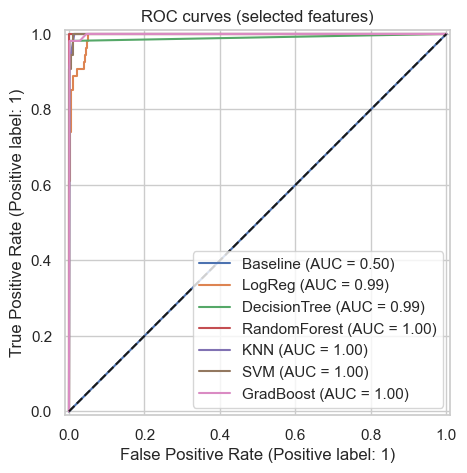

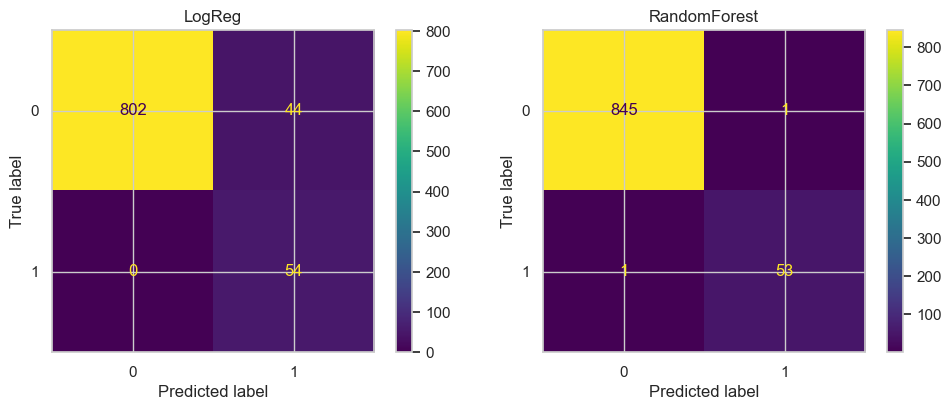

In [50]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

# ROC curves for all models on the selected feature set
fig, ax = plt.subplots(figsize=(6, 5))
for name in models:
    RocCurveDisplay.from_estimator(fitted[("selected", name)], X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--")      # diagonal = random guessing
plt.title("ROC curves (selected features)")
plt.show()

# Confusion matrices for two contrasting models
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["LogReg", "RandomForest"]):
    ConfusionMatrixDisplay.from_estimator(fitted[("selected", name)], X_test, y_test, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [51]:
"""
Model	                   Full features Selected features
Baseline (always “Legitimate”)	94.0%	94.0%
Logistic regression         	94.9%	95.1%
Decision tree	                99.8%	99.8%
Random forest	                99.9%	99.8%
KNN	                            95.7%	99.3%
SVM	                            96.2%	97.7%
Gradient boosting	            99.8%	99.8%

"""

'\nModel\t                   Full features Selected features\nBaseline (always “Legitimate”)\t94.0%\t94.0%\nLogistic regression         \t94.9%\t95.1%\nDecision tree\t                99.8%\t99.8%\nRandom forest\t                99.9%\t99.8%\nKNN\t                            95.7%\t99.3%\nSVM\t                            96.2%\t97.7%\nGradient boosting\t            99.8%\t99.8%\n\n'

Step 6: Unsupervised learning

In [52]:
# Prepare the data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

sel_cols = ["ClaimAmount", "PatientIncome", "AmountToIncome"]   # selected in Step 4
scaler = StandardScaler()
X_clu = scaler.fit_transform(X[sel_cols])        # X comes from Step 4 (no target inside)

true_fraud = y                                   # for interpretation only
orig_cluster = df_clean["Cluster"]               # the original column we dropped in Step 4

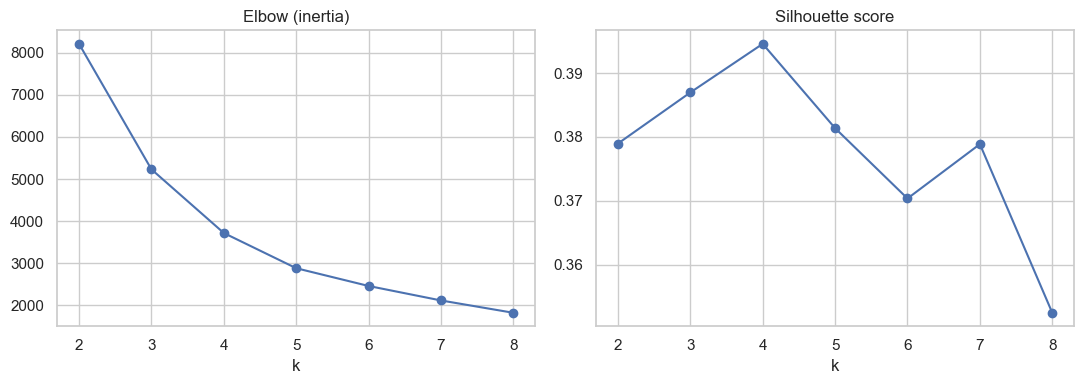

Silhouette       : 0.39459879223754396
Davies-Bouldin   : 0.8128621776165498
Calinski-Harabasz: 3941.4390733689906
   ClaimAmount  PatientIncome  AmountToIncome
0      7607.35       39702.01            0.21
1      7523.65      105290.18            0.08
2      2695.98       54503.40            0.05
3      2607.31      118253.19            0.02
Fraud     0    1
row_0           
0       448  270
1      1451    0
2      1213    0
3      1118    0
ARI vs Fraud  : 0.05211272880585997
ARI vs Cluster: 0.27403590671646977
ARI (income only vs Cluster): 0.9804659192527634


In [53]:
# K-Means
# 1. Try several values of k
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_clu)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_clu, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertia, "o-"); axes[0].set_title("Elbow (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(ks, sil, "o-");     axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

# 2. Fit the chosen k
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_clu)
labels_km = km4.labels_

# 3. Internal metrics (use only the data and labels)
print("Silhouette       :", silhouette_score(X_clu, labels_km))
print("Davies-Bouldin   :", davies_bouldin_score(X_clu, labels_km))
print("Calinski-Harabasz:", calinski_harabasz_score(X_clu, labels_km))

# 4. Describe each cluster in original units
centers = pd.DataFrame(scaler.inverse_transform(km4.cluster_centers_), columns=sel_cols)
print(centers.round(2))

# 5. Compare with known labels (interpretation only)
print(pd.crosstab(labels_km, true_fraud))
print("ARI vs Fraud  :", adjusted_rand_score(true_fraud, labels_km))
print("ARI vs Cluster:", adjusted_rand_score(orig_cluster, labels_km))

# 6. Where does the original 'Cluster' column come from?
inc = StandardScaler().fit_transform(df_clean[["PatientIncome"]])
km_inc = KMeans(n_clusters=4, n_init=10, random_state=42).fit(inc)
print("ARI (income only vs Cluster):", adjusted_rand_score(orig_cluster, km_inc.labels_))

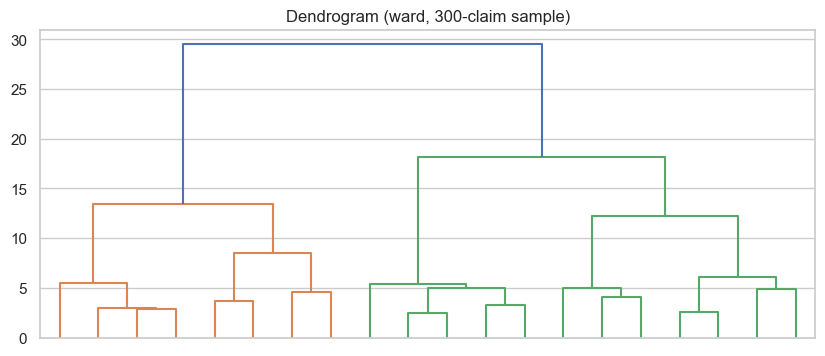

2 silhouette: 0.437 sizes: [4016  484]
3 silhouette: 0.334 sizes: [2347  484 1669]
4 silhouette: 0.308 sizes: [1669  932 1415  484]
Fraud     0    1
row_0           
0      4013    3
1       217  267
ARI vs Fraud: 0.6443085054308862


In [54]:
# Hierarchical Clustering
from scipy.cluster.hierarchy import linkage, dendrogram

# Dendrogram on a random sample of 300 claims (4,500 would be unreadable)
idx = np.random.RandomState(42).choice(len(X_clu), 300, replace=False)
Z = linkage(X_clu[idx], method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True)
plt.title("Dendrogram (ward, 300-claim sample)"); plt.show()

# Fit on all data
for k in [2, 3, 4]:
    agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
    lab = agg.fit_predict(X_clu)
    print(k, "silhouette:", round(silhouette_score(X_clu, lab), 3), "sizes:", np.bincount(lab))

labels_agg = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X_clu)
print(pd.crosstab(labels_agg, true_fraud))
print("ARI vs Fraud:", adjusted_rand_score(true_fraud, labels_agg))

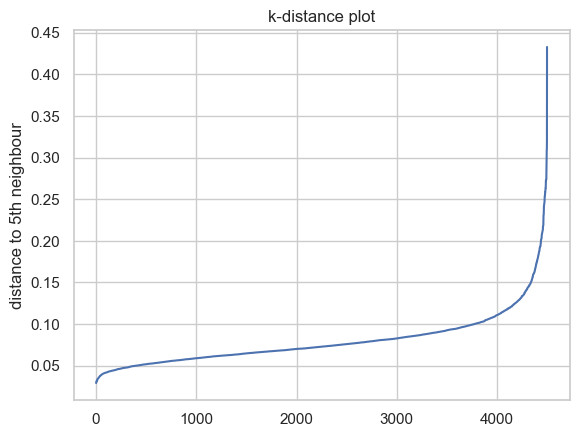

[0.073 0.114 0.137 0.211]
clusters: 3 | noise points: 14
 0    4472
-1      14
 2       9
 1       5
Name: count, dtype: int64
Fraud     0    1
row_0           
-1        2   12
 0     4228  244
 1        0    5
 2        0    9
Silhouette: 0.5372107420745453


In [55]:
# DBSCAN
# 1. k-distance plot to help choose eps
nn = NearestNeighbors(n_neighbors=6).fit(X_clu)         # 6 = the point itself + 5 neighbours
dist = np.sort(nn.kneighbors(X_clu)[0][:, -1])
plt.plot(dist); plt.ylabel("distance to 5th neighbour"); plt.title("k-distance plot"); plt.show()
print(np.percentile(dist, [50, 90, 95, 99]).round(3))

# 2. Fit DBSCAN
db = DBSCAN(eps=0.2, min_samples=5).fit(X_clu)
labels_db = db.labels_
n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print("clusters:", n_clusters, "| noise points:", (labels_db == -1).sum())
print(pd.Series(labels_db).value_counts())
print(pd.crosstab(labels_db, true_fraud))

# 3. Silhouette on non-noise points only (needs at least 2 clusters)
mask = labels_db != -1
if n_clusters > 1:
    print("Silhouette:", silhouette_score(X_clu[mask], labels_db[mask]))

[0.613 0.34  0.047] [0.613 0.953 1.   ]
     ClaimAmount  PatientIncome  AmountToIncome
PC1         0.51          -0.48            0.71
PC2         0.68           0.73           -0.00
PC3        -0.52           0.49            0.70


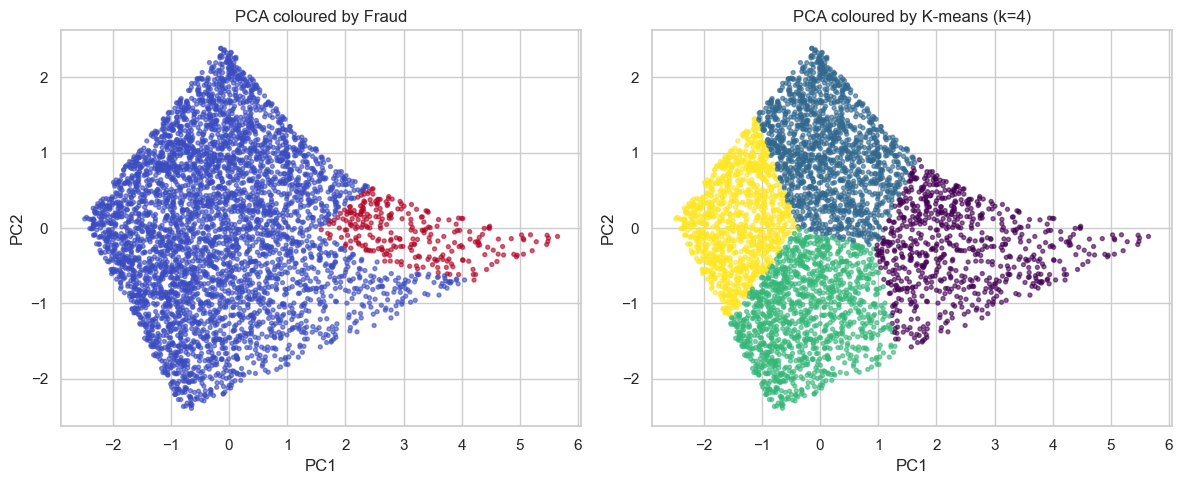

Variance in first 2 PCs: 0.35
Components needed for 90%: 22


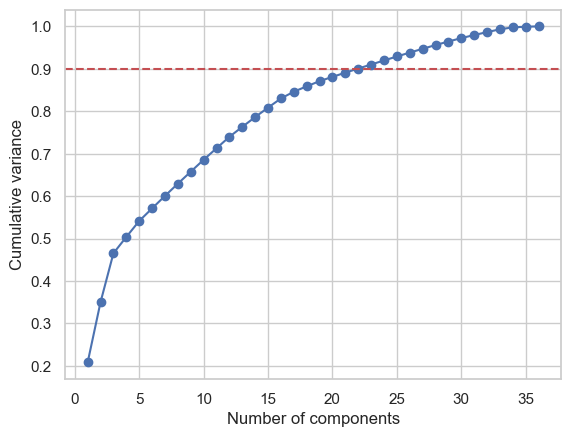

In [56]:
# PCA
# 1. PCA on the 3 selected features
pca = PCA(n_components=3).fit(X_clu)
print(pca.explained_variance_ratio_.round(3), pca.explained_variance_ratio_.cumsum().round(3))
print(pd.DataFrame(pca.components_, columns=sel_cols, index=["PC1", "PC2", "PC3"]).round(2))

# 2. Project to 2D and colour by Fraud and by K-means cluster
X_pca = PCA(n_components=2).fit_transform(X_clu)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=true_fraud, cmap="coolwarm", s=8, alpha=0.6)
axes[0].set_title("PCA coloured by Fraud")
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap="viridis", s=8, alpha=0.6)
axes[1].set_title("PCA coloured by K-means (k=4)")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

# 3. PCA on the full 36-feature set
X_full = preprocessor.fit_transform(X)
X_full = X_full.toarray() if hasattr(X_full, "toarray") else X_full   # PCA needs a dense array
pca_full = PCA().fit(X_full)
cum = pca_full.explained_variance_ratio_.cumsum()
print("Variance in first 2 PCs:", cum[1].round(3))
print("Components needed for 90%:", np.argmax(cum >= 0.90) + 1)
plt.plot(range(1, len(cum) + 1), cum, "o-"); plt.axhline(0.9, color="r", linestyle="--")
plt.xlabel("Number of components"); plt.ylabel("Cumulative variance"); plt.show()

Model Evaluation

In [62]:
#Evaluate the best individual model

In [57]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

# Build the complete pipeline
log_pipe = Pipeline([
    ("preprocessor", sel_prep),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train using training data only
log_pipe.fit(X_train, y_train)

# Predict class labels and fraud probabilities
y_pred = log_pipe.predict(X_test)
y_prob = log_pipe.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.951
Precision: 0.551
Recall   : 1.0
F1-score : 0.711
ROC-AUC  : 0.994

Confusion Matrix:
[[802  44]
 [  0  54]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       846
           1       0.55      1.00      0.71        54

    accuracy                           0.95       900
   macro avg       0.78      0.97      0.84       900
weighted avg       0.97      0.95      0.96       900



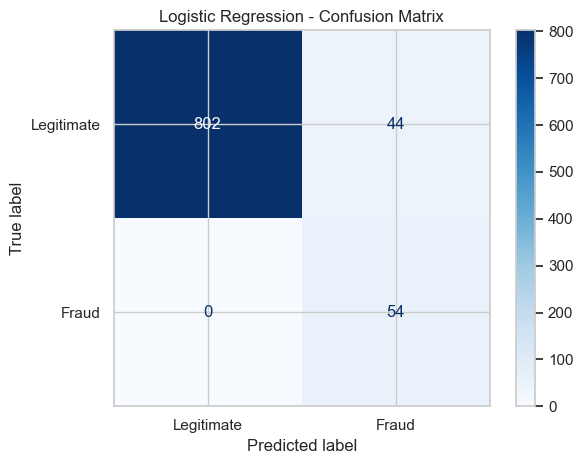

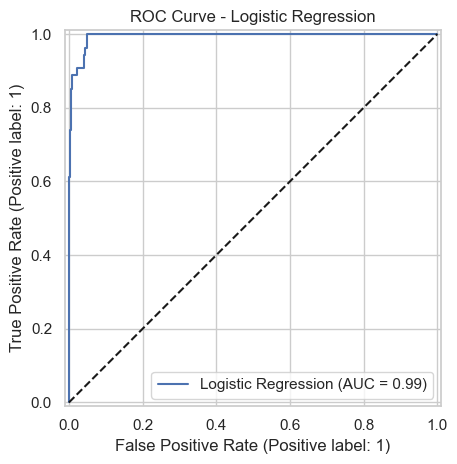

In [58]:
#Visualize the errors

# Confusion matrix
ConfusionMatrixDisplay.from_estimator(
    log_pipe,
    X_test,
    y_test,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

# ROC curve
RocCurveDisplay.from_estimator(
    log_pipe,
    X_test,
    y_test,
    name="Logistic Regression"
)

plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC Curve - Logistic Regression")
plt.tight_layout()
plt.show()

In [59]:
#Compare all models

import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", max_depth=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(
        kernel="rbf", class_weight="balanced",
        probability=True, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
fitted_models = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", sel_prep),
        ("model", model)
    ])

    # Cross-validation on training data only
    cv_scores = cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="f1"
    )

    # Fit final model and evaluate once on test data
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]

    fitted_models[name] = pipe

    results.append({
        "Model": name,
        "CV F1 Mean": cv_scores.mean(),
        "CV F1 Std": cv_scores.std(),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).round(3)

print(
    results_df.sort_values(
        "F1-score", ascending=False
    ).to_string(index=False)
)

              Model  CV F1 Mean  CV F1 Std  Accuracy  Precision  Recall  F1-score  ROC-AUC
      Decision Tree       0.983      0.017     0.998      0.981   0.981     0.981    0.990
  Gradient Boosting       0.981      0.015     0.998      0.981   0.981     0.981    0.999
      Random Forest       0.988      0.019     0.998      0.981   0.981     0.981    1.000
                KNN       0.969      0.010     0.993      0.980   0.907     0.942    0.999
                SVM       0.826      0.021     0.977      0.720   1.000     0.837    0.999
Logistic Regression       0.720      0.026     0.951      0.551   1.000     0.711    0.994
           Baseline       0.000      0.000     0.940      0.000   0.000     0.000    0.500


In [60]:
#Check Overfitting

from sklearn.metrics import f1_score

overfit_rows = []

for name, pipe in fitted_models.items():
    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)

    train_f1 = f1_score(
        y_train, train_pred, zero_division=0
    )
    test_f1 = f1_score(
        y_test, test_pred, zero_division=0
    )

    overfit_rows.append({
        "Model": name,
        "Training F1": round(train_f1, 3),
        "Test F1": round(test_f1, 3),
        "Gap": round(train_f1 - test_f1, 3)
    })

overfit_df = pd.DataFrame(overfit_rows)
print(overfit_df.sort_values("Gap", ascending=False))

                 Model  Training F1  Test F1    Gap
4                  KNN        0.981    0.942  0.039
1  Logistic Regression        0.731    0.711  0.020
2        Decision Tree        1.000    0.981  0.019
6    Gradient Boosting        1.000    0.981  0.019
3        Random Forest        1.000    0.981  0.019
0             Baseline        0.000    0.000  0.000
5                  SVM        0.831    0.837 -0.006


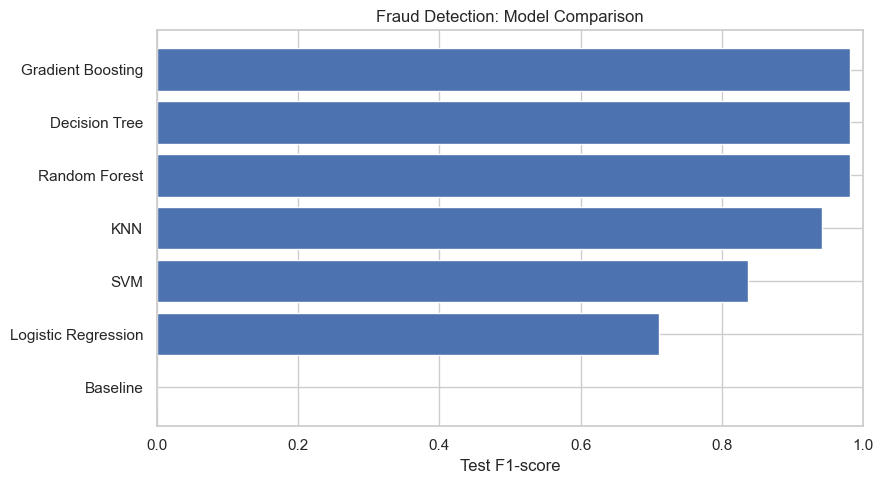

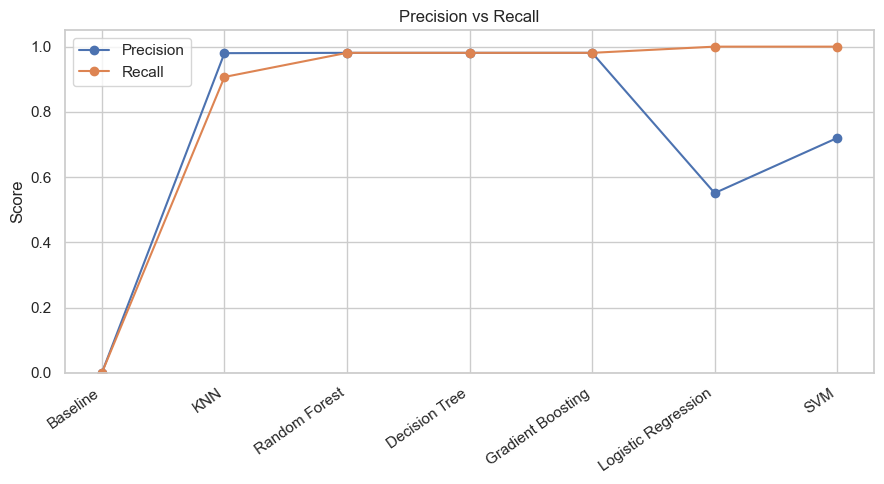

In [61]:
#Plot the model comparison

# Compare test-set F1 scores
plot_df = results_df.sort_values("F1-score")

plt.figure(figsize=(9, 5))
plt.barh(plot_df["Model"], plot_df["F1-score"])
plt.xlabel("Test F1-score")
plt.title("Fraud Detection: Model Comparison")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

# Compare precision and recall
plot_df = results_df.sort_values("Recall")

plt.figure(figsize=(9, 5))
plt.plot(plot_df["Model"], plot_df["Precision"], "o-", label="Precision")
plt.plot(plot_df["Model"], plot_df["Recall"], "o-", label="Recall")
plt.ylabel("Score")
plt.title("Precision vs Recall")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

In [63]:
#Evaluate K-Means

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

# Internal cluster evaluation
print("Silhouette Score:",
      round(silhouette_score(X_clu, labels_km), 3))

print("Davies-Bouldin Score:",
      round(davies_bouldin_score(X_clu, labels_km), 3))

print("Calinski-Harabasz Score:",
      round(calinski_harabasz_score(X_clu, labels_km), 3))

# Cluster sizes
print("\nCluster Sizes:")
print(pd.Series(labels_km).value_counts().sort_index())

# Interpret clusters using the fraud labels AFTER clustering
print("\nFraud Distribution by K-Means Cluster:")
print(pd.crosstab(
    labels_km,
    y,
    rownames=["Cluster"],
    colnames=["Actual Fraud Label"]
))

print("\nFraud Rate per Cluster:")
print(
    pd.DataFrame({"Cluster": labels_km, "Fraud": np.asarray(y)})
    .groupby("Cluster")["Fraud"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"count": "Claims", "sum": "Fraud Cases",
                     "mean": "Fraud Rate"})
    .round(3)
)

Silhouette Score: 0.395
Davies-Bouldin Score: 0.813
Calinski-Harabasz Score: 3941.439

Cluster Sizes:
0     718
1    1451
2    1213
3    1118
Name: count, dtype: int64

Fraud Distribution by K-Means Cluster:
Actual Fraud Label     0    1
Cluster                      
0                    448  270
1                   1451    0
2                   1213    0
3                   1118    0

Fraud Rate per Cluster:
         Claims  Fraud Cases  Fraud Rate
Cluster                                 
0           718          270       0.376
1          1451            0       0.000
2          1213            0       0.000
3          1118            0       0.000


In [64]:
# Evaluate Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering

hierarchy_rows = []
hierarchy_labels = {}

for k in [2, 3, 4]:
    labels = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    ).fit_predict(X_clu)

    hierarchy_labels[k] = labels

    hierarchy_rows.append({
        "Clusters": k,
        "Silhouette": silhouette_score(X_clu, labels),
        "Davies-Bouldin": davies_bouldin_score(X_clu, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_clu, labels),
        "Smallest Cluster": pd.Series(labels).value_counts().min(),
        "Largest Cluster": pd.Series(labels).value_counts().max(),
        "ARI vs Fraud": adjusted_rand_score(y, labels)
    })

hierarchy_results = pd.DataFrame(hierarchy_rows).round(3)
print(hierarchy_results.to_string(index=False))

# Examine the 2-cluster solution
labels_agg = hierarchy_labels[2]

print("\nFraud Distribution:")
print(pd.crosstab(labels_agg, y))

 Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz  Smallest Cluster  Largest Cluster  ARI vs Fraud
        2       0.437           0.755           2125.026               484             4016         0.644
        3       0.334           1.029           2647.045               484             2347         0.147
        4       0.308           0.954           2916.782               484             1669         0.080

Fraud Distribution:
Fraud     0    1
row_0           
0      4013    3
1       217  267


In [65]:
# Evaluate DBSCAN

from sklearn.cluster import DBSCAN

# Use the DBSCAN result from Step 6 if it already exists.
# Otherwise, fit the same configuration again.
db = DBSCAN(eps=0.2, min_samples=5)
labels_db = db.fit_predict(X_clu)

n_clusters = len(set(labels_db) - {-1})
noise_mask = labels_db == -1

print("Number of clusters:", n_clusters)
print("Noise points:", noise_mask.sum())
print("Noise percentage:", round(noise_mask.mean() * 100, 2), "%")

print("\nCluster sizes:")
print(pd.Series(labels_db).value_counts().sort_index())

print("\nFraud distribution by DBSCAN label:")
print(pd.crosstab(labels_db, y))

# Internal metrics on non-noise points
non_noise = ~noise_mask
non_noise_labels = labels_db[non_noise]

if len(np.unique(non_noise_labels)) >= 2:
    print("\nSilhouette (non-noise points only):",
          round(silhouette_score(
              X_clu[non_noise], non_noise_labels
          ), 3))
else:
    print("\nSilhouette unavailable: fewer than 2 non-noise clusters.")

# Post-hoc check: how many fraud cases are detected as noise?
fraud = np.asarray(y).astype(int)
tp_noise = int(((fraud == 1) & noise_mask).sum())
fp_noise = int(((fraud == 0) & noise_mask).sum())
fn_noise = int(((fraud == 1) & ~noise_mask).sum())

print("\nNoise-based fraud detection (post-hoc):")
print("Fraud cases flagged as noise:", tp_noise)
print("Legitimate cases flagged as noise:", fp_noise)
print("Fraud cases missed:", fn_noise)
print("Precision:", round(
    tp_noise / (tp_noise + fp_noise), 3
) if tp_noise + fp_noise else 0)
print("Recall:", round(
    tp_noise / (tp_noise + fn_noise), 3
) if tp_noise + fn_noise else 0)

Number of clusters: 3
Noise points: 14
Noise percentage: 0.31 %

Cluster sizes:
-1      14
 0    4472
 1       5
 2       9
Name: count, dtype: int64

Fraud distribution by DBSCAN label:
Fraud     0    1
row_0           
-1        2   12
 0     4228  244
 1        0    5
 2        0    9

Silhouette (non-noise points only): 0.537

Noise-based fraud detection (post-hoc):
Fraud cases flagged as noise: 12
Legitimate cases flagged as noise: 2
Fraud cases missed: 258
Precision: 0.857
Recall: 0.044


Component  Explained Variance  Cumulative Variance
      PC1               0.613                0.613
      PC2               0.340                0.953
      PC3               0.047                1.000

Components needed for 90% variance: 2


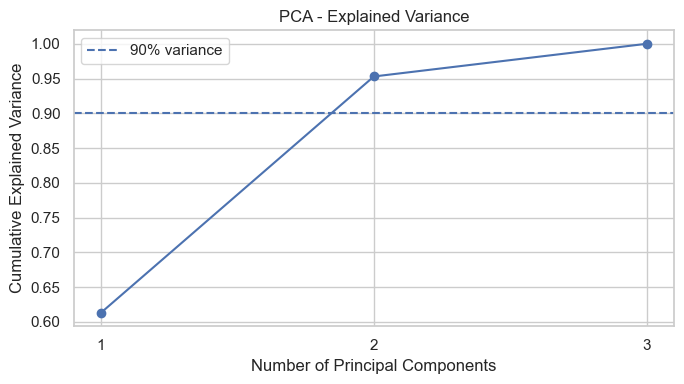

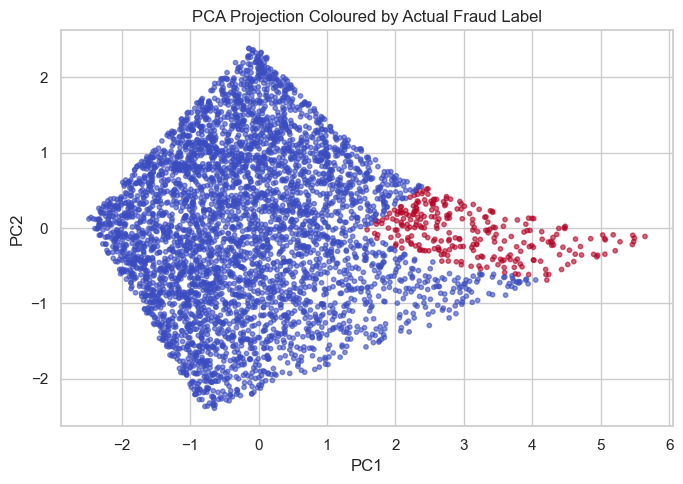

In [66]:
# Evaluate PCA

from sklearn.decomposition import PCA

# X_clu is already standardized
pca = PCA().fit(X_clu)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

pca_results = pd.DataFrame({
    "Component": [
        f"PC{i+1}" for i in range(len(explained))
    ],
    "Explained Variance": explained,
    "Cumulative Variance": cumulative
})

print(pca_results.round(3).to_string(index=False))

print("\nComponents needed for 90% variance:",
      np.argmax(cumulative >= 0.90) + 1)

# Plot cumulative explained variance
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumulative) + 1), cumulative, "o-")
plt.axhline(0.90, linestyle="--", label="90% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.xticks(range(1, len(cumulative) + 1))
plt.legend()
plt.tight_layout()
plt.show()

# Visualize the claims in two dimensions
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_clu)

plt.figure(figsize=(7, 5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=np.asarray(y), cmap="coolwarm",
    s=10, alpha=0.6
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection Coloured by Actual Fraud Label")
plt.tight_layout()
plt.show()

In [67]:
# Final Comparison table

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

clusterings = {
    "K-Means (k=4)": labels_km,
    "Hierarchical (k=2)": labels_agg,
    "DBSCAN": labels_db
}

comparison = []

for name, labels in clusterings.items():
    # DBSCAN noise points are excluded from internal metrics.
    if name == "DBSCAN":
        mask = labels != -1
        X_eval = X_clu[mask]
        lab_eval = labels[mask]
    else:
        X_eval = X_clu
        lab_eval = labels

    n_groups = len(set(lab_eval))

    if n_groups >= 2 and n_groups < len(lab_eval):
        sil = silhouette_score(X_eval, lab_eval)
        dbi = davies_bouldin_score(X_eval, lab_eval)
        chi = calinski_harabasz_score(X_eval, lab_eval)
    else:
        sil, dbi, chi = np.nan, np.nan, np.nan

    comparison.append({
        "Method": name,
        "Clusters (excluding noise)": len(set(labels) - {-1}),
        "Noise Points": int((labels == -1).sum()),
        "Silhouette": sil,
        "Davies-Bouldin": dbi,
        "Calinski-Harabasz": chi,
        "ARI vs Fraud": adjusted_rand_score(y, labels)
    })

comparison_df = pd.DataFrame(comparison).round(3)
print(comparison_df.to_string(index=False))

            Method  Clusters (excluding noise)  Noise Points  Silhouette  Davies-Bouldin  Calinski-Harabasz  ARI vs Fraud
     K-Means (k=4)                           4             0       0.395           0.813           3941.439         0.052
Hierarchical (k=2)                           2             0       0.437           0.755           2125.026         0.644
            DBSCAN                           3            14       0.537           0.323             69.300         0.155


In [68]:

# ============================================================
# FINAL PROJECT SUMMARY
# Health Insurance Claims Analysis and Fraud Detection
# ============================================================

print("=" * 65)
print(" HEALTH INSURANCE CLAIMS ANALYSIS & FRAUD DETECTION")
print("=" * 65)

print("\n1. DATASET SUMMARY")
print("-" * 65)
print(f"Total claims             : {len(df_clean)}")
print(f"Fraudulent claims        : {(y == 1).sum()}")
print(f"Legitimate claims        : {(y == 0).sum()}")
print(f"Fraud percentage         : {y.mean() * 100:.2f}%")

print("\n2. SUPERVISED LEARNING")
print("-" * 65)

# Uses results_df from Step 7
best_model = results_df.loc[results_df["F1-score"].idxmax()]

print(f"Best model by test F1    : {best_model['Model']}")
print(f"Test F1-score            : {best_model['F1-score']:.3f}")
print(f"Test accuracy            : {best_model['Accuracy']:.3f}")
print(f"Test precision           : {best_model['Precision']:.3f}")
print(f"Test recall              : {best_model['Recall']:.3f}")

print("\n3. UNSUPERVISED LEARNING")
print("-" * 65)
print("K-Means              : Customer/claim grouping")
print("Hierarchical         : Hierarchical claim clustering")
print("DBSCAN               : Density-based outlier detection")
print("PCA                  : Dimensionality reduction")

print("\n4. KEY FINDINGS")
print("-" * 65)
print("• Claim amount and patient income are important signals.")
print("• Feature selection improved some classification models.")
print("• Clustering identified groups associated with fraud labels.")
print("• Accuracy alone is insufficient for imbalanced fraud data.")
print("• Synthetic-data patterns limit real-world generalization.")

print("\n5. FINAL CONCLUSION")
print("-" * 65)
print("The project demonstrates an end-to-end machine learning")
print("workflow for insurance claim analysis and fraud detection.")
print("Independent validation is required before real-world use.")

print("\n" + "=" * 65)
print("                 PROJECT COMPLETED")
print("=" * 65)

 HEALTH INSURANCE CLAIMS ANALYSIS & FRAUD DETECTION

1. DATASET SUMMARY
-----------------------------------------------------------------
Total claims             : 4500
Fraudulent claims        : 270
Legitimate claims        : 4230
Fraud percentage         : 6.00%

2. SUPERVISED LEARNING
-----------------------------------------------------------------
Best model by test F1    : Decision Tree
Test F1-score            : 0.981
Test accuracy            : 0.998
Test precision           : 0.981
Test recall              : 0.981

3. UNSUPERVISED LEARNING
-----------------------------------------------------------------
K-Means              : Customer/claim grouping
Hierarchical         : Hierarchical claim clustering
DBSCAN               : Density-based outlier detection
PCA                  : Dimensionality reduction

4. KEY FINDINGS
-----------------------------------------------------------------
• Claim amount and patient income are important signals.
• Feature selection improved some cl